# Tasko — What really drives growth before the Series A?

**IMT 2026 — Growth Modeling & Data-Driven Strategy — Final project**

Tasko is a product-led B2B SaaS for team task management: a free plan for everyone, paid plans billed per seat (Pro 8 €, Business 12 € per seat and per month). The board wants to know whether growth really comes from the product, as the founders believe, or from paid search, the largest marketing line.

The notebook follows the five guiding questions of the brief:

0. Data cleaning and cleaning log
1. Funnel and growth loop — where does value leak?
2. Channels and segments — does the difference survive a like-for-like comparison?
3. Unit economics — CAC, retention, LTV, payback
4. What changed during the 18 months, and what it caused
5. North Star Metric
6. Growth model: backtest and three scenarios
7. A/B test plan

All figures are saved in the `figures/` folder and reused in the report and the slides.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

plt.rcParams.update({
    "figure.figsize": (8, 4.2),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 10,
})

COLORS = {"organic_direct": "#4C72B0", "paid_search": "#DD8452", "content_seo": "#55A868",
          "invite_loop": "#C44E52", "partners": "#8172B3"}
CHANNELS = list(COLORS)
EXTRACTION = pd.Timestamp("2026-06-30")

def save(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

## 0. Data cleaning

The four files come straight from production. We first measure what is wrong, then apply one rule at a time and record how many rows each rule affects.

In [2]:
ws_raw = pd.read_csv("data/workspaces.csv", dtype=str)
users_raw = pd.read_csv("data/users.csv", dtype=str)
rev_raw = pd.read_csv("data/monthly_revenue.csv", dtype=str)
spend_raw = pd.read_csv("data/marketing_spend.csv", dtype=str)

for name, df in [("workspaces", ws_raw), ("users", users_raw), ("monthly_revenue", rev_raw), ("marketing_spend", spend_raw)]:
    print(f"{name:16s} {df.shape[0]:>6} rows | exact duplicates: {df.duplicated().sum()}")

workspaces         9932 rows | exact duplicates: 0
users             47901 rows | exact duplicates: 474
monthly_revenue    4424 rows | exact duplicates: 22
marketing_spend      54 rows | exact duplicates: 0


In [3]:
print(ws_raw["acquisition_channel"].value_counts(dropna=False), "\n")
print(ws_raw["company_size"].value_counts(dropna=False), "\n")
print(users_raw["role"].value_counts(dropna=False), "\n")

# date patterns: every digit replaced by 9
pattern = users_raw["joined_date"].str.replace(r"\d", "9", regex=True)
print(pattern.value_counts())

acquisition_channel
organic_direct    3270
paid_search       2790
content_seo       2034
invite_loop       1351
partners           486
internal             1
Name: count, dtype: int64 

company_size
1-10        5339
11-50       2585
51-200       882
1–10         607
NaN          267
11 to 50     127
11–50        125
Name: count, dtype: int64 

role
member    37872
owner     10029
Name: count, dtype: int64 

joined_date
9999-99-99    46934
99/99/9999      967
Name: count, dtype: int64


The first profiling already shows several issues: one `internal` workspace, four spellings of company size (`1-10`, `1–10`, `11 to 50`, `11–50`), 267 missing sizes, exact duplicates in `users` and `monthly_revenue`, and two date formats in `users.joined_date`. There are 10,029 owners for 9,932 workspaces, which the duplicates explain.

In [4]:
log = []

def add_log(table, rule, rows, action):
    log.append({"table": table, "rule": rule, "rows affected": int(rows), "action": action})

In [5]:
ws = ws_raw.copy()

# 1. internal / test account
internal = ws["acquisition_channel"].eq("internal") | ~ws["workspace_id"].str.match(r"^W\d{5}$")
add_log("workspaces", "Internal account (W_INTERNAL, channel 'internal')", internal.sum(), "removed")
ws = ws[~internal]

# 2. inconsistent size labels ('1–10', '11 to 50', ...)
size_clean = ws["company_size"].str.replace("–", "-").str.replace(" to ", "-")
add_log("workspaces", "Inconsistent company_size labels harmonised", (size_clean != ws["company_size"]).sum() - ws["company_size"].isna().sum(), "relabelled")
ws["company_size"] = size_clean

# 3. missing size
add_log("workspaces", "Missing company_size", ws["company_size"].isna().sum(), "set to 'unknown'")
ws["company_size"] = ws["company_size"].fillna("unknown")

ws["created_date"] = pd.to_datetime(ws["created_date"], format="%Y-%m-%d")
ws["upgrade_date"] = pd.to_datetime(ws["upgrade_date"], format="%Y-%m-%d")

# 4. consistency checks
add_log("workspaces", "Upgrade before creation or after extraction", ((ws["upgrade_date"] < ws["created_date"]) | (ws["upgrade_date"] > EXTRACTION)).sum(), "check only")
add_log("workspaces", "Upgrade date without plan (or plan without date)", (ws["upgrade_date"].isna() != ws["plan"].isna()).sum(), "check only")

# 5. invite_loop workspace created before its origin workspace (impossible)
origin_date = ws.set_index("workspace_id")["created_date"]
ws["origin_created"] = ws["origin_workspace_id"].map(origin_date)
impossible = ws["origin_created"] > ws["created_date"]
add_log("workspaces", "invite_loop workspace created before its origin workspace", impossible.sum(), "kept, excluded from loop timing")
ws["loop_date_error"] = impossible
ws.shape

(9931, 9)

In [6]:
users = users_raw.copy()

n = users.duplicated().sum()
users = users.drop_duplicates()
add_log("users", "Exact duplicate rows", n, "removed")

internal = ~users["user_id"].str.match(r"^U\d{6}$") | ~users["workspace_id"].isin(ws["workspace_id"])
add_log("users", "Users of the internal workspace", internal.sum(), "removed")
users = users[~internal]

# mixed date formats: 'YYYY-MM-DD' and 'DD/MM/YYYY' (day > 12 appears, so day comes first)
is_fr = users["joined_date"].str.contains("/")
add_log("users", "joined_date in DD/MM/YYYY format", is_fr.sum(), "converted")
iso_dates = pd.to_datetime(users["joined_date"].where(~is_fr), format="%Y-%m-%d")
fr_dates = pd.to_datetime(users["joined_date"].where(is_fr), format="%d/%m/%Y")
users["joined_date"] = iso_dates.fillna(fr_dates)

add_log("users", "Duplicate user_id after deduplication", users["user_id"].duplicated().sum(), "check only")
add_log("users", "Joined after 30 June 2026", (users["joined_date"] > EXTRACTION).sum(), "check only")

created = users["workspace_id"].map(ws.set_index("workspace_id")["created_date"])
add_log("users", "Joined before the workspace was created", (users["joined_date"] < created).sum(), "check only")

unknown_inviter = users["invited_by_user_id"].notna() & ~users["invited_by_user_id"].isin(users["user_id"])
add_log("users", "Inviter not found in users table", unknown_inviter.sum(), "kept (member still valid)")
users.shape

(47287, 5)

The `DD/MM/YYYY` dates are read as day-first because the first field goes up to 31. Once converted, no user joins before the creation of their workspace nor after the extraction date, which validates the rule.
The 1,591 members whose inviter is absent from the table are kept: the membership itself is valid, only the inviter link is missing.

In [7]:
rev = rev_raw.copy()

n = rev.duplicated().sum()
rev = rev.drop_duplicates()
add_log("monthly_revenue", "Exact duplicate rows", n, "removed")

rev["month"] = pd.to_datetime(rev["month"], format="%Y-%m-%d")
rev["seats"] = rev["seats"].astype(int)
rev["mrr_eur"] = rev["mrr_eur"].astype(float)

add_log("monthly_revenue", "Negative MRR (sign error: |MRR| = seats x price)", (rev["mrr_eur"] < 0).sum(), "absolute value")
rev["mrr_eur"] = rev["mrr_eur"].abs()

add_log("monthly_revenue", "Same workspace billed twice in a month", rev.duplicated(["workspace_id", "month"]).sum(), "check only")

# MRR must equal seats x list price (8 EUR pro, 12 EUR business)
plan = rev["workspace_id"].map(ws.set_index("workspace_id")["plan"])
price = plan.map({"pro": 8, "business": 12})
add_log("monthly_revenue", "MRR different from seats x list price", (rev["mrr_eur"] != rev["seats"] * price).sum(), "check only")
add_log("monthly_revenue", "Revenue for an unknown or free workspace", plan.isna().sum(), "check only")

rev["plan"] = plan
rev.shape

(4402, 5)

The 25 negative MRR values are not refunds: in every case |MRR| equals seats × list price exactly, so they are sign errors. After correction, every invoice matches seats × price (8 € Pro, 12 € Business).

In [8]:
# first billed month vs upgrade month
first_bill = rev.groupby("workspace_id")["month"].min()
paid = ws.dropna(subset=["upgrade_date"]).set_index("workspace_id")
lag = (first_bill.dt.to_period("M") - paid.loc[first_bill.index, "upgrade_date"].dt.to_period("M")).apply(lambda x: x.n)
print("Months between upgrade and first invoice:\n", lag.value_counts())

no_rev = paid[~paid.index.isin(rev["workspace_id"])]
print("\nPaying workspaces with no invoice yet, by upgrade month:\n", no_rev["upgrade_date"].dt.to_period("M").value_counts())
add_log("monthly_revenue", "Upgraded workspaces with no invoice (all upgraded in June 2026)", len(no_rev), "kept (billed from next month)")

Months between upgrade and first invoice:
 1    775
Name: count, dtype: int64

Paying workspaces with no invoice yet, by upgrade month:
 upgrade_date
2026-06    76
Freq: M, Name: count, dtype: int64


Every paying workspace receives its first invoice in the month that follows the upgrade. The 76 workspaces upgraded in June 2026 without any invoice are therefore not an error: they will be billed from July 2026, after the extraction date.

In [9]:
spend = spend_raw.copy()
spend["month"] = pd.to_datetime(spend["month"], format="%Y-%m-%d")
spend["spend_eur"] = spend["spend_eur"].astype(float)

add_log("marketing_spend", "Missing, negative or duplicated spend", (spend["spend_eur"] <= 0).sum() + spend.duplicated(["month", "channel"]).sum(), "check only")
print(spend.groupby("channel")["spend_eur"].agg(["count", "min", "max", "sum"]))

             count     min      max       sum
channel                                      
content_seo     18  3000.0   5550.0   76950.0
paid_search     18  6000.0  11690.0  153890.0
partners        18  2500.0   2500.0   45000.0


In [10]:
cleaning_log = pd.DataFrame(log)
cleaning_log.to_csv("figures/cleaning_log.csv", index=False)
cleaning_log

,table,rule,rows affected,action
0,workspaces,"Internal account (W_INTERNAL, channel 'internal')",1,removed
1,workspaces,Inconsistent company_size labels harmonised,859,relabelled
2,workspaces,Missing company_size,267,set to 'unknown'
3,workspaces,Upgrade before creation or after extraction,0,check only
4,workspaces,Upgrade date without plan (or plan without date),0,check only
5,workspaces,invite_loop workspace created before its origi...,66,"kept, excluded from loop timing"
6,users,Exact duplicate rows,474,removed
7,users,Users of the internal workspace,140,removed
8,users,joined_date in DD/MM/YYYY format,956,converted
9,users,Duplicate user_id after deduplication,0,check only


**Cleaning log.** Seven rules modify the data (1 internal workspace and its 140 users removed, 474 + 22 duplicates removed, 859 sizes relabelled, 267 sizes set to `unknown`, 956 dates converted, 25 MRR signs corrected); the other lines are consistency checks that return zero or that we deliberately keep. The marketing file is clean. Note that `organic_direct` and `invite_loop` have no spend line: their CAC is zero by construction.

### Variables used in the analysis

- **Activation**: at least 2 teammates join the workspace within 30 days of its creation (justified in section 1).
- **Conversion**: upgrade to a paid plan within 90 days. The longest observed delay is 89 days, so only cohorts created before April 2026 are fully observed (*mature cohorts*).
- **Churn**: a paying workspace whose last invoice is before June 2026.

In [11]:
ws["created_month"] = ws["created_date"].dt.to_period("M").dt.to_timestamp()
ws["upgraded"] = ws["upgrade_date"].notna()
ws["days_to_upgrade"] = (ws["upgrade_date"] - ws["created_date"]).dt.days
ws["after_change"] = ws["created_date"] >= "2025-09-15"   # see section 5

# teammates invited in the first 7 / 30 days of the workspace
members = users[users["role"] == "member"].merge(ws[["workspace_id", "created_date"]], on="workspace_id")
members["days"] = (members["joined_date"] - members["created_date"]).dt.days
ws["team_7d"] = ws["workspace_id"].map(members[members["days"] <= 7].groupby("workspace_id").size()).fillna(0)
ws["team_30d"] = ws["workspace_id"].map(members[members["days"] <= 30].groupby("workspace_id").size()).fillna(0)

paying_june = rev.loc[rev["month"] == "2026-06-01", "workspace_id"]
ws["paying_june"] = ws["workspace_id"].isin(paying_june)

print(ws["days_to_upgrade"].describe())

count    851.000000
mean      46.104583
std       22.987252
min       10.000000
25%       26.000000
50%       44.000000
75%       66.000000
max       89.000000
Name: days_to_upgrade, dtype: float64


## 1. Funnel and growth loop

### 1.1 Finding the activation step (Aha moment)

The AARRR framework needs an activation event: the moment the user experiences the core value. For a team tool, value is collaboration, so we look at conversion according to the number of teammates invited during the first month.

In [12]:
# cohorts created before April 2026 have had 90 days to convert (max observed delay: 89 days)
mature = ws[ws["created_date"] < "2026-04-01"].copy()
mature["paid_90d"] = mature["days_to_upgrade"] <= 90

aha = mature.groupby(mature["team_30d"].clip(upper=6))["paid_90d"].agg(["count", "mean"])
aha.columns = ["workspaces", "conversion_90d"]
aha

,workspaces,conversion_90d
team_30d,,
0.0,1919,0.052632
1.0,1958,0.058733
2.0,1560,0.125000
3.0,974,0.131417
4.0,565,0.150442
5.0,303,0.161716
6.0,277,0.176895


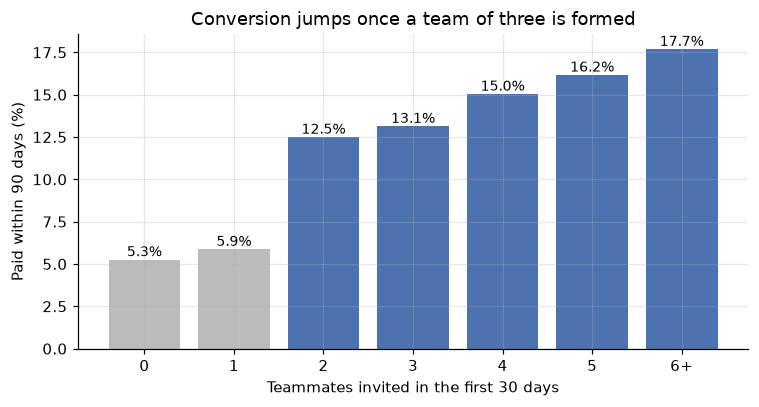

In [13]:
labels = ["0", "1", "2", "3", "4", "5", "6+"]
plt.figure(figsize=(7, 3.8))
bars = plt.bar(labels, aha["conversion_90d"] * 100, color=["#BBBBBB"] * 2 + ["#4C72B0"] * 5)
plt.bar_label(bars, fmt="%.1f%%", fontsize=9)
plt.xlabel("Teammates invited in the first 30 days")
plt.ylabel("Paid within 90 days (%)")
plt.title("Conversion jumps once a team of three is formed")
save("fig01_aha_moment")

Conversion is flat at 5–6 % for workspaces with 0 or 1 teammate, then **more than doubles from 2 teammates onwards** (12.5 %) and keeps rising (17.7 % with 6+). The threshold is sharp, so we define activation as *a team of three: the owner plus at least two teammates within 30 days*.

In [14]:
ws["activated"] = ws["team_30d"] >= 2
mature["activated"] = mature["team_30d"] >= 2
print(mature.groupby("activated")["paid_90d"].agg(["count", "mean"]))

           count      mean
activated                 
False       3877  0.055713
True        3679  0.137537


                                    count  % of created  % of previous step
Workspace created                    7556         100.0                 NaN
Activated\n(2+ teammates, 30 days)   3679          48.7                48.7
Paid within 90 days                   722           9.6                19.6
Still paying\nin June 2026            593           7.8                82.1


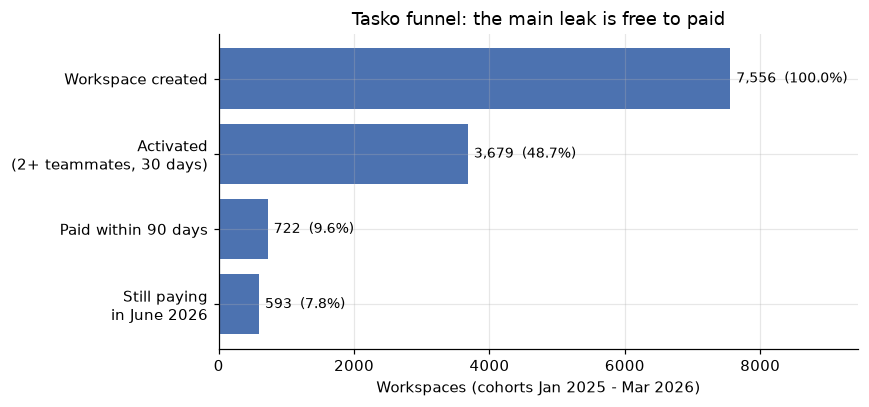

In [15]:
funnel = pd.Series({
    "Workspace created": len(mature),
    "Activated\n(2+ teammates, 30 days)": mature["activated"].sum(),
    "Paid within 90 days": mature["paid_90d"].sum(),
    "Still paying\nin June 2026": mature["paying_june"].sum(),
})
step = funnel / funnel.shift(1)
print(pd.DataFrame({"count": funnel, "% of created": (funnel / funnel.iloc[0] * 100).round(1), "% of previous step": (step * 100).round(1)}))

plt.figure(figsize=(8, 3.8))
bars = plt.barh(funnel.index[::-1], funnel.values[::-1], color="#4C72B0")
plt.bar_label(bars, labels=[f"{v:,.0f}  ({v / funnel.iloc[0]:.1%})" for v in funnel.values[::-1]], padding=4, fontsize=9)
plt.xlim(0, funnel.iloc[0] * 1.25)
plt.xlabel("Workspaces (cohorts Jan 2025 - Mar 2026)")
plt.title("Tasko funnel: the main leak is free to paid")
save("fig02_funnel")

In [16]:
# where do the paying workspaces come from?
print(pd.crosstab(mature["activated"], mature["paid_90d"], margins=True))
print("\nShare of 90-day conversions coming from activated workspaces:",
      round(mature.loc[mature["paid_90d"], "activated"].mean(), 3))

paid_90d   False  True   All
activated                   
False       3661   216  3877
True        3173   506  3679
All         6834   722  7556

Share of 90-day conversions coming from activated workspaces: 0.701


**Reading the funnel.** Out of 7,556 workspaces created between January 2025 and March 2026, 48.7 % reach activation, 9.6 % pay within 90 days and 7.8 % are still paying in June 2026. Once a workspace pays, it tends to stay (82 % of converted workspaces still pay at extraction). **The main leak is the free-to-paid step**, and it is largely driven by activation: activated workspaces convert at 13.8 % against 5.6 % for the others, and they represent 70 % of all conversions.

In the language of the course, the funnel *describes* the leak; activation is the lever that controls it.

### 1.2 The growth loop

Tasko has an acquisition loop: a user invited as a guest in a workspace later creates their own workspace (`invite_loop`). The loop is real only if the output of one cycle feeds the input of the next.

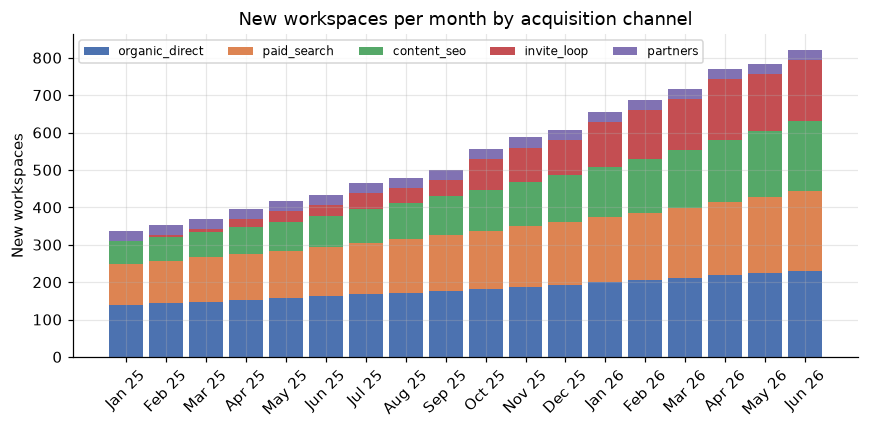

acquisition_channel  organic_direct  paid_search  content_seo  invite_loop  partners
created_month                                                                       
2025-01-01                     41.7         32.4         17.9          0.0       8.0
2025-09-01                     35.4         29.8         20.6          8.8       5.4
2026-06-01                     28.1         25.8         23.0         19.8       3.3


In [17]:
new_ws = pd.crosstab(ws["created_month"], ws["acquisition_channel"])[CHANNELS]

fig, ax = plt.subplots(figsize=(8, 4))
labels = [d.strftime("%b %y") for d in new_ws.index]
bottom = np.zeros(len(new_ws))
for c in CHANNELS:
    ax.bar(labels, new_ws[c], bottom=bottom, color=COLORS[c], label=c, width=0.85)
    bottom += new_ws[c].values
ax.tick_params(axis="x", rotation=45)
ax.set_ylabel("New workspaces")
ax.set_title("New workspaces per month by acquisition channel")
ax.legend(fontsize=8, ncol=5, loc="upper left")
save("fig03_new_workspaces")

share = new_ws.div(new_ws.sum(axis=1), axis=0)
print((share.iloc[[0, 8, -1]] * 100).round(1))

The loop is visible in the acquisition mix: `invite_loop` grows from 0 % of new workspaces in January 2025 to 8.8 % in September 2025 and **19.8 % in June 2026**, while the share of paid search falls from 32.4 % to 25.8 %.

K (180 days), before vs after change:
 after_change
False    0.086
True     0.123
Name: children_180d, dtype: float64



Median delay origin -> new workspace (days): 146.0


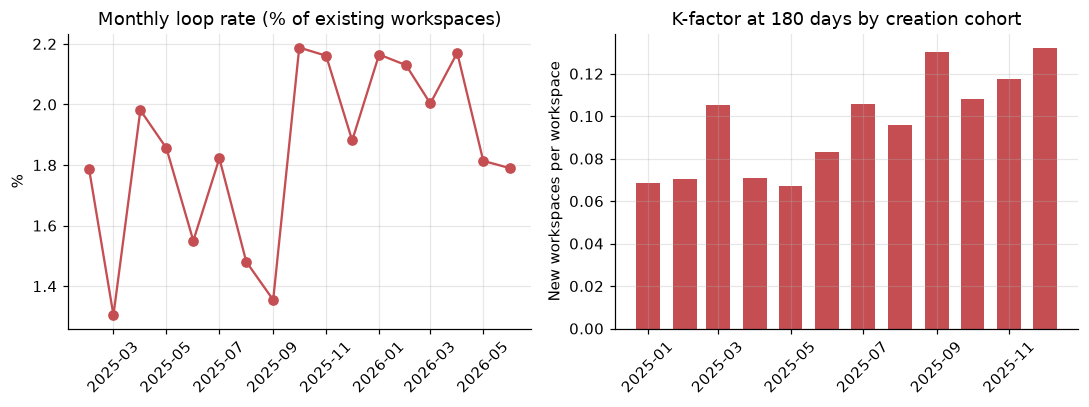

In [18]:
# monthly loop rate: invite_loop workspaces created in month t / workspaces existing at the end of t-1
stock = new_ws.sum(axis=1).cumsum().shift(1)
loop_rate = new_ws["invite_loop"] / stock

# K over 180 days: invite_loop workspaces generated by each workspace within 180 days of its creation
child = ws[(ws["acquisition_channel"] == "invite_loop") & ~ws["loop_date_error"]]
child_lag = (child["created_date"] - child["origin_created"]).dt.days
children_180 = child[child_lag <= 180].groupby("origin_workspace_id").size()
ws["children_180d"] = ws["workspace_id"].map(children_180).fillna(0)

old = ws[ws["created_date"] < "2026-01-01"]        # 180 days observable
k_by_cohort = old.groupby("created_month")["children_180d"].mean()
print("K (180 days), before vs after change:\n", old.groupby("after_change")["children_180d"].mean().round(3))
print("\nMedian delay origin -> new workspace (days):", child_lag.median())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(loop_rate.index, loop_rate * 100, marker="o", color=COLORS["invite_loop"])
axes[0].set_title("Monthly loop rate (% of existing workspaces)")
axes[0].set_ylabel("%")
axes[1].bar(k_by_cohort.index, k_by_cohort.values, width=20, color=COLORS["invite_loop"])
axes[1].set_title("K-factor at 180 days by creation cohort")
axes[1].set_ylabel("New workspaces per workspace")
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
save("fig04_invite_loop")

In [19]:
# does the loop depend on activation or payment of the origin workspace?
print(old.groupby("activated")["children_180d"].mean().round(3))
print(old.groupby("upgraded")["children_180d"].mean().round(3))
print(old.groupby("acquisition_channel")["children_180d"].mean().round(3))

activated
False    0.100
True     0.099
Name: children_180d, dtype: float64
upgraded
False    0.099
True     0.110
Name: children_180d, dtype: float64
acquisition_channel
content_seo       0.096
invite_loop       0.115
organic_direct    0.101
paid_search       0.093
partners          0.111
Name: children_180d, dtype: float64


**Effective K-factor.** The course defines K = i × c (invites × conversion). The data does not contain the invitations sent to guests, so we measure the *effective* virality directly: each workspace generates on average **0.09 new workspaces within 180 days before mid-September 2025 and 0.12 after**. The monthly loop rate stays around 1.5–2.2 % of the existing base.

Three conclusions follow:

- **K ≈ 0.1 is far below 1**: the loop does not replace acquisition, it multiplies it. It is also below the 0.3–0.8 "sweet spot" mentioned in the course.
- The loop is **slow**: the median delay between an origin workspace and the workspace it generates is 146 days.
- The loop rate does **not** depend on activation, payment or channel of the origin workspace (≈ 0.10 everywhere). The loop is fed by the *size of the base*, not by its quality. This is why it compounds: its absolute output grows with the stock of workspaces.

## 2. Channels and segments

### 2.1 Raw comparison

In [20]:
# monthly logo churn on paying workspaces: last invoice before June 2026 = churn
last_bill = rev.groupby("workspace_id")["month"].max()
rev["churn_next"] = rev["month"].eq(rev["workspace_id"].map(last_bill)) & (rev["month"] < "2026-06-01")
rev = rev.merge(ws[["workspace_id", "acquisition_channel", "company_size"]], on="workspace_id", how="left")
observed = rev[rev["month"] < "2026-06-01"]

kpi = pd.DataFrame({
    "workspaces": ws.groupby("acquisition_channel").size(),
    "activation": mature.groupby("acquisition_channel")["activated"].mean(),
    "conv_90d": mature.groupby("acquisition_channel")["paid_90d"].mean(),
    "seats": rev.groupby("acquisition_channel")["seats"].mean(),
    "arpa_eur": rev.groupby("acquisition_channel")["mrr_eur"].mean(),
    "monthly_churn": observed.groupby("acquisition_channel")["churn_next"].mean(),
}).loc[CHANNELS]
kpi.round(3)

,workspaces,activation,conv_90d,seats,arpa_eur,monthly_churn
acquisition_channel,,,,,,
organic_direct,3270,0.570,0.107,3.985,35.003,0.031
paid_search,2790,0.292,0.064,3.069,27.483,0.027
content_seo,2034,0.562,0.113,4.047,37.813,0.037
invite_loop,1351,0.592,0.118,4.112,36.225,0.033
partners,486,0.496,0.077,4.274,38.212,0.046


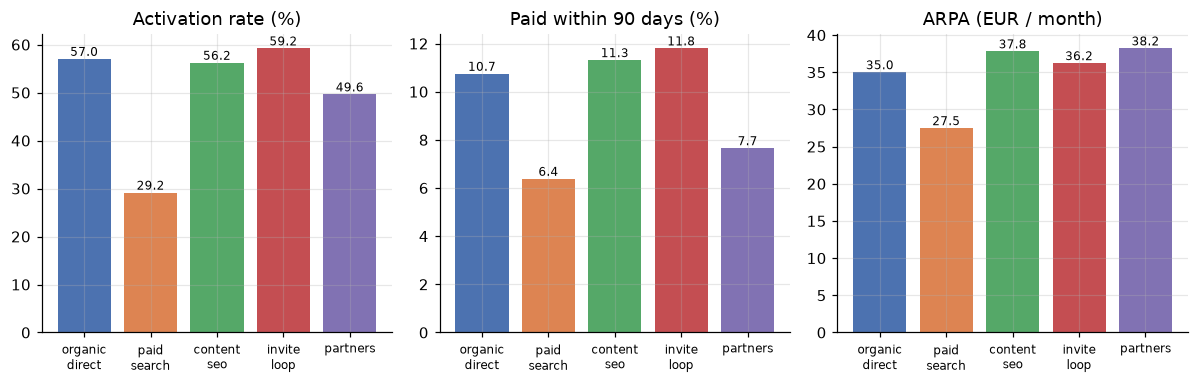

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, col, title in zip(axes, ["activation", "conv_90d", "arpa_eur"],
                          ["Activation rate (%)", "Paid within 90 days (%)", "ARPA (EUR / month)"]):
    values = kpi[col] * (100 if col != "arpa_eur" else 1)
    bars = ax.bar(range(5), values, color=[COLORS[c] for c in CHANNELS])
    ax.bar_label(bars, fmt="%.1f", fontsize=8)
    ax.set_xticks(range(5))
    ax.set_xticklabels([c.replace("_", "\n") for c in CHANNELS], fontsize=8)
    ax.set_title(title)
save("fig05_channel_kpis")

Paid search stands out on every early indicator: activation of 29 % against 50–59 % for the other channels, 90-day conversion of 6.4 % against 10.7–11.8 % for organic, SEO and loop, and the smallest teams (3.1 seats, 27 € ARPA against 35–38 €). Partners also convert poorly (7.7 %) and churn the most (4.6 % per month). Paid search churn looks low (2.7 %), but it rests on few churn events.

### 2.2 Like-for-like comparison

A difference between channels can be a composition effect (e.g. a channel bringing smaller companies). We therefore compare within the same company size, and within the same activation status.

In [22]:
sizes = ["1-10", "11-50", "51-200"]
by_size = mature.pivot_table(index="acquisition_channel", columns="company_size", values="paid_90d", aggfunc="mean")[sizes].loc[CHANNELS]
by_act = mature.pivot_table(index="acquisition_channel", columns="activated", values="paid_90d", aggfunc="mean").loc[CHANNELS]
by_act.columns = ["not activated", "activated"]
table = pd.concat([by_size, by_act], axis=1)
print((table * 100).round(1))
print("\nSize mix by channel (%):")
print((pd.crosstab(ws["acquisition_channel"], ws["company_size"], normalize="index")[sizes] * 100).round(1))

                     1-10  11-50  51-200  not activated  activated
acquisition_channel                                               
organic_direct        9.7   11.9    14.4            5.7       14.5
paid_search           5.7    7.7     8.3            4.9       10.1
content_seo          11.0    9.2    17.0            7.4       14.3
invite_loop           9.8   14.0    18.1            5.9       15.9
partners              5.9    7.4    21.9            3.4       11.9

Size mix by channel (%):
company_size         1-10  11-50  51-200
acquisition_channel                     
content_seo          59.7   28.8     8.6
invite_loop          60.8   27.5     9.0
organic_direct       60.2   28.3     9.1
paid_search          58.8   29.5     8.8
partners             61.7   26.5     8.6


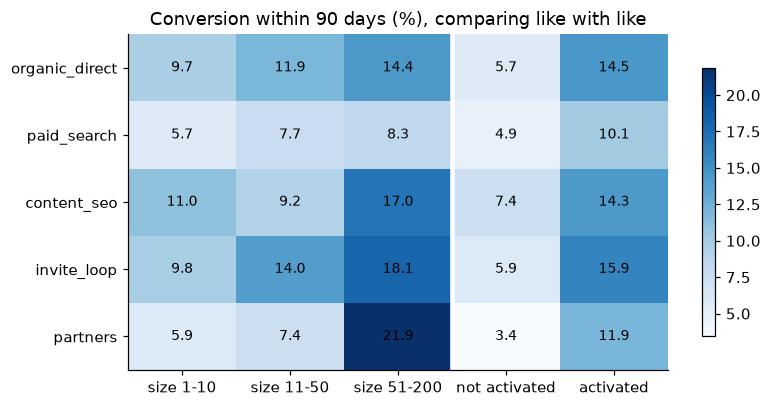

In [23]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
im = ax.imshow(table.values * 100, cmap="Blues", aspect="auto")
ax.set_xticks(range(table.shape[1]))
ax.set_xticklabels(["size 1-10", "size 11-50", "size 51-200", "not activated", "activated"])
ax.set_yticks(range(5))
ax.set_yticklabels(CHANNELS)
for i in range(table.shape[0]):
    for j in range(table.shape[1]):
        ax.text(j, i, f"{table.values[i, j] * 100:.1f}", ha="center", va="center", fontsize=9)
ax.axvline(2.5, color="white", lw=3)
ax.grid(False)
ax.set_title("Conversion within 90 days (%), comparing like with like")
plt.colorbar(im, ax=ax, shrink=0.8)
save("fig06_like_for_like")

**The paid search gap survives the like-for-like comparison.**

- The size mix is almost identical across channels (≈ 60 % / 29 % / 9 %), so company size cannot explain the gap; and within each size, paid search converts the least (5.7 % / 7.7 % / 8.3 %).
- Even **among activated workspaces**, paid search converts at 10.1 % against 14–16 % for organic, SEO and loop. Paid search users are less likely to form a team *and* less likely to pay once they do.

The other channels are close to each other once like is compared with like. Partners' high value on 51–200 rests on very few workspaces and should not be over-interpreted.

In [24]:
seg = pd.DataFrame({
    "seats": rev.groupby("company_size")["seats"].mean(),
    "arpa_eur": rev.groupby("company_size")["mrr_eur"].mean(),
    "monthly_churn": observed.groupby("company_size")["churn_next"].mean(),
    "conv_90d": mature.groupby("company_size")["paid_90d"].mean(),
})
plan_seg = pd.DataFrame({
    "arpa_eur": rev.groupby("plan")["mrr_eur"].mean(),
    "monthly_churn": observed.groupby("plan")["churn_next"].mean(),
})
print(seg.round(3), "\n")
print(plan_seg.round(3))

              seats  arpa_eur  monthly_churn  conv_90d
company_size                                          
1-10          2.630    21.043          0.044     0.086
11-50         4.327    41.580          0.021     0.101
51-200        6.965    65.550          0.012     0.140
unknown       3.988    35.229          0.047     0.101 

          arpa_eur  monthly_churn
plan                             
business    63.486          0.021
pro         28.197          0.035


Company size is the strongest segment driver of value: workspaces of 51–200 employees have 7 seats, 66 € ARPA and 1.2 % monthly churn, against 2.6 seats, 21 € and 4.4 % for teams of 1–10. Business-plan workspaces churn less than Pro (2.1 % vs 3.5 %). Retention, as the course stresses, compounds: a churn of 1.2 % instead of 4.4 % multiplies the expected lifetime by almost four.

## 3. Unit economics

### 3.1 CAC, LTV and payback by channel

- CAC = spend / paying workspaces, on cohorts January 2025 – March 2026 (conversion fully observed).
- LTV = ARPA / monthly churn, i.e. ARPA × lifetime with lifetime = 1 / churn. The data pack gives no gross margin, so this is a **revenue LTV** (an upper bound of the margin LTV).
- Payback = CAC / ARPA, in months.

In [25]:
# spend and conversions of cohorts Jan 2025 - Mar 2026 (conversion fully observed)
spend_m = spend[spend["month"] < "2026-04-01"].groupby("channel")["spend_eur"].sum()
signups = mature.groupby("acquisition_channel").size()
payers = mature.groupby("acquisition_channel")["upgraded"].sum()

ue = pd.DataFrame({"spend": spend_m, "signups": signups, "payers": payers}).loc[CHANNELS].fillna(0)
ue["cost_per_signup"] = ue["spend"] / ue["signups"]
ue["cac_paying"] = (ue["spend"] / ue["payers"]).replace(0, np.nan)   # no spend for organic and loop
ue["arpa"] = kpi["arpa_eur"]
ue["churn"] = kpi["monthly_churn"]
ue["ltv"] = ue["arpa"] / ue["churn"]             # revenue LTV (no gross margin in the data pack)
ue["ltv_cac"] = ue["ltv"] / ue["cac_paying"]
ue["payback_months"] = ue["cac_paying"] / ue["arpa"]

blended_cac = ue["spend"].sum() / ue["payers"].sum()
paid_cac = ue["spend"].sum() / ue.loc[["paid_search", "content_seo", "partners"], "payers"].sum()
print(f"Blended CAC (all payers): {blended_cac:.0f} EUR | CAC of paid channels only: {paid_cac:.0f} EUR")
ue.round({"spend": 0, "cost_per_signup": 1, "cac_paying": 0, "arpa": 1, "churn": 3, "ltv": 0, "ltv_cac": 2, "payback_months": 1})

Blended CAC (all payers): 302 EUR | CAC of paid channels only: 642 EUR


,spend,signups,payers,cost_per_signup,cac_paying,arpa,churn,ltv,ltv_cac,payback_months
organic_direct,0.0,2597,279,0.0,NaN,35.0,0.031,1144.0,NaN,NaN
paid_search,120150.0,2178,139,55.2,864.0,27.5,0.027,1007.0,1.16,31.5
content_seo,60750.0,1503,170,40.4,357.0,37.8,0.037,1022.0,2.86,9.5
invite_loop,0.0,873,103,0.0,NaN,36.2,0.033,1111.0,NaN,NaN
partners,37500.0,405,31,92.6,1210.0,38.2,0.046,830.0,0.69,31.7


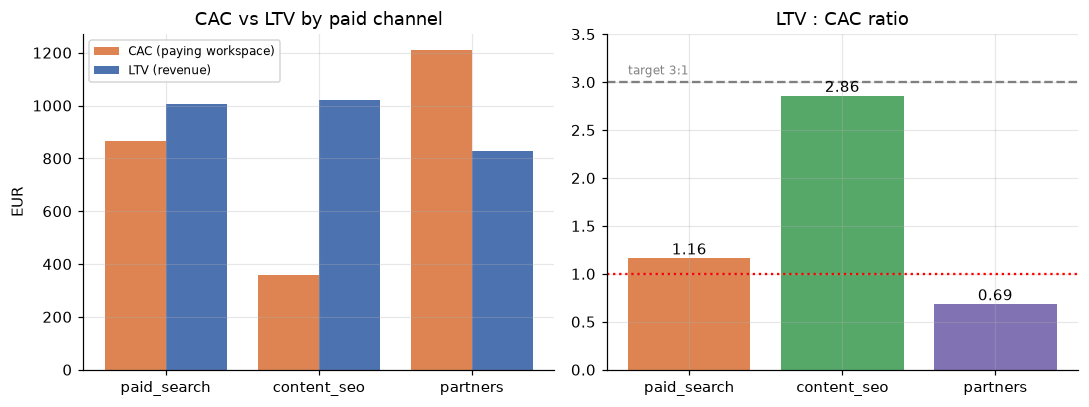

In [26]:
paid_ch = ["paid_search", "content_seo", "partners"]
x = np.arange(len(paid_ch))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].bar(x - 0.2, ue.loc[paid_ch, "cac_paying"], 0.4, label="CAC (paying workspace)", color="#DD8452")
axes[0].bar(x + 0.2, ue.loc[paid_ch, "ltv"], 0.4, label="LTV (revenue)", color="#4C72B0")
axes[0].set_xticks(x)
axes[0].set_xticklabels(paid_ch)
axes[0].set_ylabel("EUR")
axes[0].legend(fontsize=8)
axes[0].set_title("CAC vs LTV by paid channel")

bars = axes[1].bar(paid_ch, ue.loc[paid_ch, "ltv_cac"], color=[COLORS[c] for c in paid_ch])
axes[1].bar_label(bars, fmt="%.2f")
axes[1].axhline(3, ls="--", color="grey")
axes[1].text(-0.4, 3.08, "target 3:1", fontsize=8, color="grey")
axes[1].set_ylim(0, 3.5)
axes[1].axhline(1, ls=":", color="red")
axes[1].set_title("LTV : CAC ratio")
save("fig07_unit_economics")

| Channel | Cost per sign-up | CAC (paying) | LTV | LTV : CAC | Payback |
|---|---|---|---|---|---|
| paid_search | 55 € | 864 € | 1,007 € | 1.2 | 31 months |
| content_seo | 40 € | 357 € | 1,022 € | 2.9 | 9.5 months |
| partners | 93 € | 1,210 € | 830 € | 0.7 | 32 months |

- **Content SEO** is close to the 3:1 benchmark of the course, with a payback under 10 months.
- **Paid search** is borderline: LTV : CAC of 1.2 *on revenue*, so below 1 as soon as a gross margin is applied. A payback of 31 months is longer than the observed lifetime of most cohorts.
- **Partners** destroy value (LTV : CAC < 1).
- The blended CAC is 302 €, against 642 € for paid channels alone: half of the paying workspaces come at zero acquisition cost (organic direct and invite loop).

### 3.2 Cost per sign-up over time

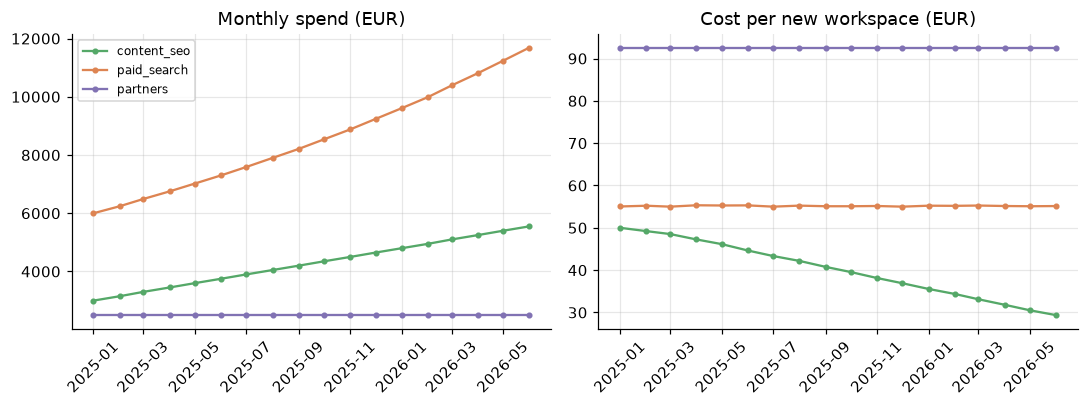

channel     content_seo  paid_search  partners
month                                         
2025-01-01         50.0         55.0      92.6
2026-06-01         29.4         55.1      92.6
Spend growth Jan 25 -> Jun 26 (x): {'content_seo': 1.85, 'paid_search': 1.95, 'partners': 1.0}


In [27]:
sp = spend.pivot(index="month", columns="channel", values="spend_eur")
cps = sp / new_ws[sp.columns]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for c in sp.columns:
    axes[0].plot(sp.index, sp[c], marker="o", ms=3, color=COLORS[c], label=c)
    axes[1].plot(cps.index, cps[c], marker="o", ms=3, color=COLORS[c], label=c)
axes[0].set_title("Monthly spend (EUR)")
axes[1].set_title("Cost per new workspace (EUR)")
axes[0].legend(fontsize=8)
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
save("fig08_spend_and_cost_per_signup")
print(cps.iloc[[0, -1]].round(1))
print("Spend growth Jan 25 -> Jun 26 (x):", (sp.iloc[-1] / sp.iloc[0]).round(2).to_dict())

The three channels behave very differently:

- **Paid search**: spend grows by 4 % per month (×1.95 over 18 months) and the cost per sign-up stays at 55 €. There is no sign of saturation yet, but no economy of scale either: growth from this channel is *linear in spend* — a funnel that needs continuous fuel.
- **Content SEO**: spend grows linearly (+150 € per month) while sign-ups grow faster, so the cost per sign-up falls from 50 € to 29 €. This is the SEO flywheel of the course: slow to build, compounding afterwards.
- **Partners**: a flat 2,500 € for exactly 27 sign-ups every month (92.6 €), with no improvement.

### 3.3 Retention by cohort

In [28]:
first_bill = rev.groupby("workspace_id")["month"].min().rename("first_month")
rev = rev.drop(columns="first_month", errors="ignore").join(first_bill, on="workspace_id")
rev["age"] = (rev["month"].dt.year - rev["first_month"].dt.year) * 12 + (rev["month"].dt.month - rev["first_month"].dt.month)
rev["cohort"] = rev["first_month"].dt.to_period("Q").astype(str)

counts = rev.pivot_table(index="cohort", columns="age", values="workspace_id", aggfunc="nunique")
retention = counts.div(counts[0], axis=0)

# hide ages not yet fully observed for the whole cohort
cohort_end = rev.groupby("cohort")["first_month"].max()
max_age = (2026 - cohort_end.dt.year) * 12 + (6 - cohort_end.dt.month)
for c in retention.index:
    retention.loc[c, retention.columns > max_age[c]] = np.nan
(retention.iloc[:, :13] * 100).round(0)

age,0,1,2,3,4,5,6,7,8,9,10,11,12
cohort,,,,,,,,,,,,,
2025Q1,100.0,100.0,100.0,100.0,94.0,94.0,94.0,94.0,94.0,83.0,78.0,78.0,78.0
2025Q2,100.0,97.0,95.0,91.0,86.0,80.0,76.0,71.0,68.0,68.0,67.0,66.0,63.0
2025Q3,100.0,97.0,94.0,92.0,87.0,86.0,84.0,80.0,80.0,79.0,NaN,NaN,NaN
2025Q4,100.0,96.0,93.0,87.0,84.0,81.0,78.0,NaN,NaN,NaN,NaN,NaN,NaN
2026Q1,100.0,97.0,94.0,90.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026Q2,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


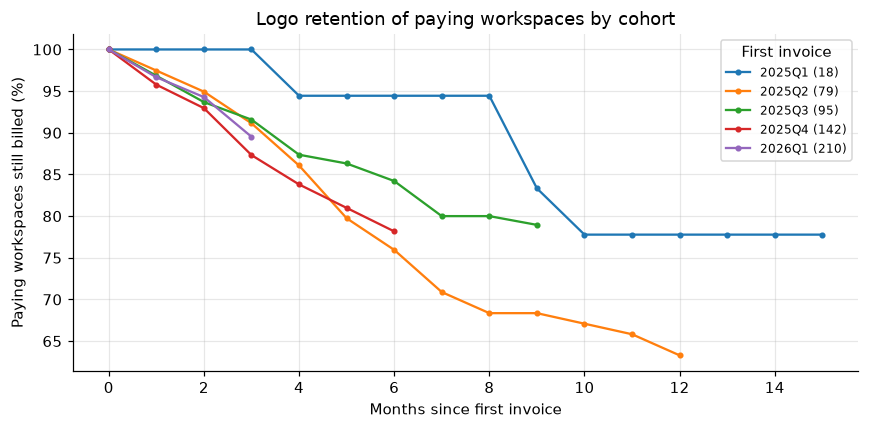

In [29]:
plt.figure(figsize=(8, 4))
for c in retention.index[:-1]:
    plt.plot(retention.columns, retention.loc[c] * 100, marker="o", ms=3, label=f"{c} ({int(counts.loc[c, 0])})")
plt.xlabel("Months since first invoice")
plt.ylabel("Paying workspaces still billed (%)")
plt.title("Logo retention of paying workspaces by cohort")
plt.legend(fontsize=8, title="First invoice")
save("fig09_retention_cohorts")

Logo retention of paying workspaces is between 76 % and 94 % after 6 months and around 63–78 % after a year for the oldest cohorts. The more recent cohorts (2025Q3, 2025Q4) do not retain worse than 2025Q2. The average monthly churn is about 3 %, i.e. an expected lifetime of roughly 30 months.

In [30]:
mrr = rev.groupby("month").agg(mrr=("mrr_eur", "sum"), paying=("workspace_id", "nunique"), seats=("seats", "sum"))
mrr["arpa"] = mrr["mrr"] / mrr["paying"]

# net revenue retention over 6 months for workspaces paying in December 2025
base = rev[rev["month"] == "2025-12-01"]
later = rev[(rev["month"] == "2026-06-01") & rev["workspace_id"].isin(base["workspace_id"])]
print(f"NRR Dec 2025 -> Jun 2026: {later['mrr_eur'].sum() / base['mrr_eur'].sum():.1%}")
print(f"Logo retention Dec 2025 -> Jun 2026: {len(later) / len(base):.1%}")
mrr.tail(7).round(1)

NRR Dec 2025 -> Jun 2026: 95.2%
Logo retention Dec 2025 -> Jun 2026: 83.6%


,mrr,paying,seats,arpa
month,,,,
2025-12-01,9272.0,293,1038,31.6
2026-01-01,11564.0,342,1288,33.8
2026-02-01,13744.0,401,1544,34.3
2026-03-01,16504.0,469,1865,35.2
2026-04-01,18580.0,514,2085,36.1
2026-05-01,21300.0,581,2390,36.7
2026-06-01,24512.0,654,2752,37.5


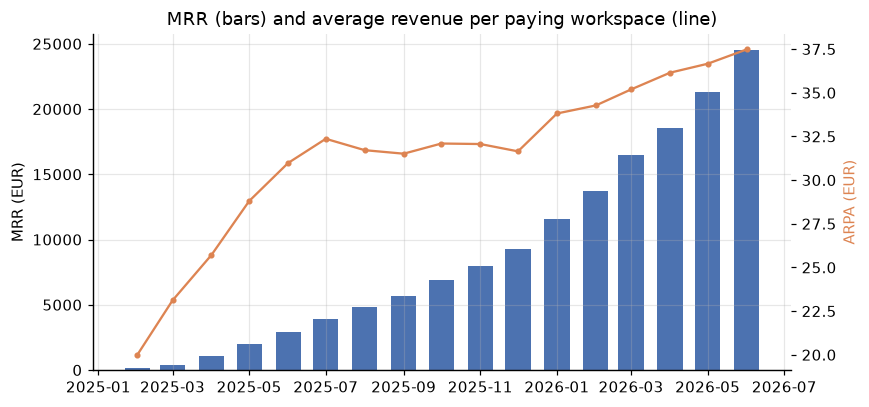

In [31]:
fig, ax1 = plt.subplots(figsize=(8, 3.8))
ax1.bar(mrr.index, mrr["mrr"], width=20, color="#4C72B0")
ax1.set_ylabel("MRR (EUR)")
ax2 = ax1.twinx()
ax2.plot(mrr.index, mrr["arpa"], color="#DD8452", marker="o", ms=3)
ax2.set_ylabel("ARPA (EUR)", color="#DD8452")
ax2.grid(False)
ax1.set_title("MRR (bars) and average revenue per paying workspace (line)")
save("fig10_mrr_arpa")

MRR grows from 140 € (February 2025) to **24,512 € in June 2026** (654 paying workspaces, 2,752 seats). ARPA rises from 31.6 € in December 2025 to 37.5 € in June 2026, but the net revenue retention over six months of the December 2025 base is 95 %: seat expansion of surviving accounts (19 % of them grew) does not fully offset churn. The rise of ARPA therefore comes mostly from **new accounts arriving with larger teams**, which is consistent with the activation improvement described below.

## 4. What changed during the 18 months?

### 4.1 Detecting the change

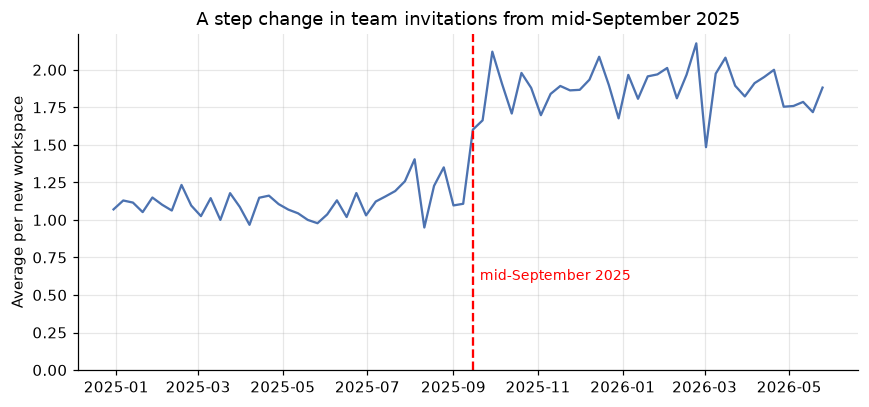

In [32]:
weekly = ws.groupby(ws["created_date"].dt.to_period("W").dt.start_time)[["team_7d"]].mean()
weekly["activation_30d"] = ws.groupby(ws["created_date"].dt.to_period("W").dt.start_time)["activated"].mean()
weekly = weekly[weekly.index < "2026-06-01"]       # last weeks not yet observed over 30 days

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(weekly.index, weekly["team_7d"], color="#4C72B0", label="Teammates invited in first 7 days")
ax.axvline(pd.Timestamp("2025-09-15"), color="red", ls="--")
ax.text(pd.Timestamp("2025-09-20"), 0.6, "mid-September 2025", color="red", fontsize=9)
ax.set_ylim(0, None)
ax.set_ylabel("Average per new workspace")
ax.set_title("A step change in team invitations from mid-September 2025")
save("fig11_change_detection")

The average number of teammates invited in the first week of a workspace jumps from about 1.1–1.4 to about 1.9–2.1 **in the second half of September 2025**, and stays at the new level. Nothing in the data pack names the cause; the shape (a step, permanent, on all channels) points to a product change in onboarding rather than to a marketing campaign. We use 15 September 2025 as the split date.

In [33]:
ba = pd.DataFrame({
    "teammates_30d": mature.groupby("after_change")["team_30d"].mean(),
    "activation": mature.groupby("after_change")["activated"].mean(),
    "conv_90d": mature.groupby("after_change")["paid_90d"].mean(),
    "K_180d": old.groupby("after_change")["children_180d"].mean(),
})
upg = ws[ws["upgraded"]].set_index("workspace_id")["upgrade_date"]
observed = rev[rev["month"] < "2026-06-01"].copy()
observed["after_change"] = observed["workspace_id"].map(upg) >= "2025-09-15"
ba["monthly_churn"] = observed.groupby("after_change")["churn_next"].mean()
ba.index = ["before", "after"]
print(ba.round(3))

conv_ch = mature.pivot_table(index="acquisition_channel", columns="after_change", values="paid_90d", aggfunc="mean").loc[CHANNELS]
act_ch = mature.pivot_table(index="acquisition_channel", columns="after_change", values="activated", aggfunc="mean").loc[CHANNELS]
conv_ch.columns = act_ch.columns = ["before", "after"]
print("\nActivation by channel:\n", (act_ch * 100).round(1))
print("\nConversion 90 days by channel:\n", (conv_ch * 100).round(1))

        teammates_30d  activation  conv_90d  K_180d  monthly_churn
before          1.382       0.383     0.081   0.086          0.032
after           2.171       0.576     0.108   0.123          0.033

Activation by channel:
                      before  after
acquisition_channel               
organic_direct         44.1   70.5
paid_search            23.6   34.5
content_seo            47.5   63.2
invite_loop            44.3   63.5
partners               40.6   61.4

Conversion 90 days by channel:
                      before  after
acquisition_channel               
organic_direct          8.5   13.0
paid_search             6.3    6.5
content_seo            10.8   11.8
invite_loop             9.8   12.4
partners                5.2   10.8


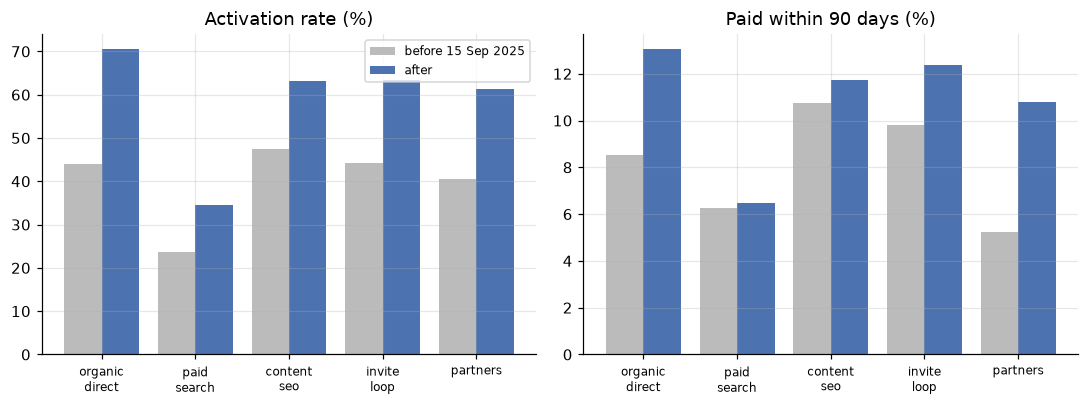

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
x = np.arange(5)
for ax, t, title in zip(axes, [act_ch, conv_ch], ["Activation rate (%)", "Paid within 90 days (%)"]):
    ax.bar(x - 0.2, t["before"] * 100, 0.4, label="before 15 Sep 2025", color="#BBBBBB")
    ax.bar(x + 0.2, t["after"] * 100, 0.4, label="after", color="#4C72B0")
    ax.set_xticks(x)
    ax.set_xticklabels([c.replace("_", "\n") for c in CHANNELS], fontsize=8)
    ax.set_title(title)
axes[0].legend(fontsize=8)
save("fig12_before_after")

**What the change caused**

- Teammates invited in 30 days: 1.38 → 2.17; activation: 38 % → 58 %.
- 90-day conversion: 8.1 % → 10.8 % (+2.7 points, +33 %).
- Effective K at 180 days: 0.086 → 0.123: more teammates means more guests exposed to the product, hence more loop output.
- Churn of paying workspaces: unchanged (3.2 % → 3.3 %). The change acted on activation and conversion, not on retention.

**Paid search is the exception**: its activation rises (24 % → 35 %) but much less than for the other channels, and its conversion does not move (6.3 % → 6.5 %).

In [35]:
# like-for-like: same channel and size, before vs after
lfl = mature[mature["company_size"] != "unknown"].pivot_table(index=["acquisition_channel", "company_size"], columns="after_change", values="paid_90d", aggfunc="mean")
lfl.columns = ["before", "after"]
lfl["diff_pts"] = (lfl["after"] - lfl["before"]) * 100
print(lfl.round(3))
print("\nCells where conversion improved:", (lfl["diff_pts"] > 0).sum(), "out of", len(lfl))

                                  before  after  diff_pts
acquisition_channel company_size                         
content_seo         1-10           0.109  0.111     0.224
                    11-50          0.088  0.095     0.720
                    51-200         0.167  0.175     0.794
invite_loop         1-10           0.066  0.107     4.174
                    11-50          0.122  0.144     2.194
                    51-200         0.235  0.167    -6.863
organic_direct      1-10           0.078  0.117     3.946
                    11-50          0.101  0.136     3.521
                    51-200         0.110  0.173     6.314
paid_search         1-10           0.055  0.059     0.398
                    11-50          0.069  0.085     1.610
                    51-200         0.118  0.051    -6.777
partners            1-10           0.041  0.084     4.302
                    11-50          0.035  0.118     8.256
                    51-200         0.158  0.308    14.980

Cells where c

The improvement holds within channel and size: conversion rises in 13 of the 15 cells. The two decreases (paid search 51–200 and invite loop 51–200) are small cells. The effect is therefore not a change of mix: it is a change in behaviour, for comparable workspaces.

Two other changes are worth noting: the paid search budget doubled without any efficiency gain, and the loop's share of acquisition more than doubled after the onboarding change.

## 5. North Star Metric

The course defines the NSM as the single metric that best captures the value delivered to users, typically a retention or engagement metric (e.g. *messages sent per team* for Slack).

**Proposed NSM: number of workspaces reaching a team of three users each month.**

joined_date
2026-01-01    493
2026-02-01    539
2026-03-01    535
2026-04-01    572
2026-05-01    596
2026-06-01    605
Name: count, dtype: int64


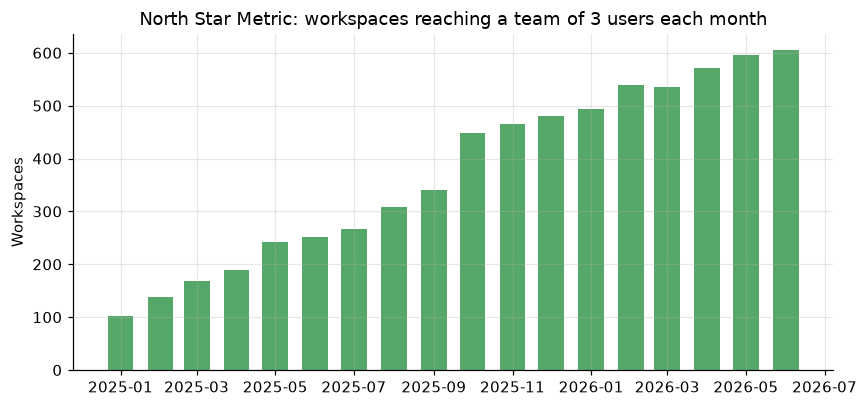

In [36]:
# NSM candidate: number of workspaces that reached a team of 3 (owner + 2 teammates) in the month
users_sorted = users.sort_values("joined_date")
users_sorted["rank"] = users_sorted.groupby("workspace_id").cumcount() + 1
team3 = users_sorted[users_sorted["rank"] == 3].set_index("workspace_id")["joined_date"]
nsm = team3.dt.to_period("M").dt.to_timestamp().value_counts().sort_index()

print(nsm.tail(6))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(nsm.index, nsm.values, width=20, color="#55A868")
ax.set_ylabel("Workspaces")
ax.set_title("North Star Metric: workspaces reaching a team of 3 users each month")
save("fig13_north_star")

Why this metric:

- **It captures the core value**: Tasko is a team tool; a workspace with three people is a workspace where collaboration actually happens.
- **It predicts revenue**: teams of three convert 2.5 times more than solo or duo workspaces, and Tasko bills per seat, so it also drives ARPA.
- **It feeds the loop**: more teammates means more guests exposed to the product.
- **It is actionable by every team**: product (onboarding), marketing (channels that bring teams, not individuals), sales-assist.
- **It is not a vanity metric**: unlike sign-ups, it does not grow with paid spend alone — paid search brings many sign-ups but few teams.

The course warns about the risk of tunnel vision. It should be read together with two guardrails: paid conversion and churn of paying workspaces. The metric reached about 600 workspaces per month in mid-2026. With usage data (tasks created, weekly active users), a stronger version would be *weekly active teams of three or more*.

## 6. Growth model

### 6.1 Structure

Following the anatomy of a growth model seen in class (inputs → parameters → outputs), the model is monthly:

| Inputs | Parameters | Outputs |
|---|---|---|
| spend per channel | cost per sign-up (paid search, SEO, partners) | new workspaces |
| | organic growth rate | paying workspaces |
| | loop rate (new loop workspaces / existing base) | MRR |
| | conversion rate and delay (1 to 4 months) | |
| | monthly churn, ARPA | |

- new workspaces(t) = spend / cost per sign-up + organic(t) + loop rate × base(t−1)
- new paying(t) = conversion × Σ lag share(k) × new workspaces(t−k)
- paying(t) = paying(t−1) × (1 − churn) + new paying(t)
- MRR(t) = paying(t) × ARPA

In [37]:
# monthly series used by the growth model
hist = pd.DataFrame(index=new_ws.index)
for c in CHANNELS:
    hist[c] = new_ws[c]
for c in ["paid_search", "content_seo", "partners"]:
    hist["spend_" + c] = sp[c]
hist["stock"] = new_ws.sum(axis=1).cumsum()
hist["paying"] = mrr["paying"]
hist["mrr"] = mrr["mrr"]
hist = hist.fillna(0)

# delay between creation month and first invoice month (1 to 4 months)
lag_months = (ws.loc[ws["upgraded"], "upgrade_date"].dt.to_period("M") - ws.loc[ws["upgraded"], "created_date"].dt.to_period("M")).apply(lambda x: x.n) + 1
print(lag_months.value_counts(normalize=True).sort_index().round(3))

1    0.114
2    0.409
3    0.347
4    0.130
Name: proportion, dtype: float64


In [38]:
def calibrate(end, mature_end):
    """Estimate the model parameters with data available up to `end` only."""
    h = hist[hist.index <= end]
    w_ = ws[ws["created_date"] < mature_end]
    r_ = rev[(rev["month"] < end) & (rev["month"] >= pd.Timestamp(end) - pd.DateOffset(months=6))]
    last6 = h.tail(6)
    p = {
        "cps_paid_search": h["spend_paid_search"].sum() / h["paid_search"].sum(),
        # SEO: cost per signup falls over time, so use the last 6 months
        "cps_content_seo": last6["spend_content_seo"].sum() / last6["content_seo"].sum(),
        "cps_partners": h["spend_partners"].sum() / h["partners"].sum(),
        "organic_growth": (last6["organic_direct"].iloc[-1] / last6["organic_direct"].iloc[0]) ** (1 / 5) - 1,
        "loop_rate": (last6["invite_loop"] / h["stock"].shift(1).tail(6)).mean(),
        "conversion": w_["upgraded"].mean(),
        "churn": r_["churn_next"].mean(),
        "arpa": h["mrr"].iloc[-1] / h["paying"].iloc[-1],
        "seo_spend_step": h["spend_content_seo"].diff().tail(6).mean(),
        "paid_spend_growth": (h["spend_paid_search"].iloc[-1] / h["spend_paid_search"].iloc[-7]) ** (1 / 6) - 1,
    }
    w_lag = lag_months[ws.loc[lag_months.index, "created_date"] < mature_end]
    p["lag"] = w_lag.value_counts(normalize=True).sort_index().to_dict()
    return p

params_bt = calibrate("2025-12-01", "2025-10-01")
{k: (round(v, 4) if isinstance(v, float) else v) for k, v in params_bt.items()}

{'cps_paid_search': np.float64(55.1437),
 'cps_content_seo': np.float64(39.8911),
 'cps_partners': np.float64(92.5926),
 'organic_growth': np.float64(0.0294),
 'loop_rate': np.float64(0.0181),
 'conversion': np.float64(0.084),
 'churn': np.float64(0.0376),
 'arpa': np.float64(31.6451),
 'seo_spend_step': np.float64(150.0),
 'paid_spend_growth': np.float64(0.0401),
 'lag': {1: 0.10158730158730159,
  2: 0.3619047619047619,
  3: 0.3873015873015873,
  4: 0.1492063492063492}}

In [39]:
def simulate(p, start, months, spend_plan, history):
    """Monthly growth model: acquisition (spend + organic + loop) -> conversion (with delay) -> churn -> MRR."""
    h = history.copy()
    rows = []
    organic = h["organic_direct"].iloc[-1]
    stock = h["stock"].iloc[-1]
    paying = h["paying"].iloc[-1]
    created = list(h[CHANNELS].sum(axis=1))          # past cohorts still converting
    for t, month in enumerate(pd.date_range(start, periods=months, freq="MS")):
        s = spend_plan.iloc[t]
        organic = organic * (1 + p["organic_growth"])
        new = {
            "paid_search": s["paid_search"] / p["cps_paid_search"],
            "content_seo": s["content_seo"] / p["cps_content_seo"],
            "partners": s["partners"] / p["cps_partners"],
            "organic_direct": organic,
            "invite_loop": p["loop_rate"] * stock,
        }
        total_new = sum(new.values())
        created.append(total_new)
        stock += total_new
        new_paying = sum(p["conversion"] * share * created[-1 - lag] for lag, share in p["lag"].items())
        paying = paying * (1 - p["churn"]) + new_paying
        rows.append({"month": month, **new, "new_workspaces": total_new, "new_paying": new_paying,
                     "paying": paying, "mrr": paying * p["arpa"]})
    return pd.DataFrame(rows).set_index("month")

### 6.2 Backtest

The model is calibrated only on data available on 31 December 2025, then run on January–June 2026 with the real spend, and compared with what actually happened.

In [40]:
actual_spend = sp[sp.index >= "2026-01-01"]
bt = simulate(params_bt, "2026-01-01", 6, actual_spend, hist[hist.index <= "2025-12-01"])

actual = pd.DataFrame({"new_workspaces": new_ws.sum(axis=1), "paying": mrr["paying"], "mrr": mrr["mrr"]}).loc["2026-01-01":]
result = pd.DataFrame({"pred_new_ws": bt["new_workspaces"], "actual_new_ws": actual["new_workspaces"],
                       "pred_paying": bt["paying"], "actual_paying": actual["paying"],
                       "pred_mrr": bt["mrr"], "actual_mrr": actual["mrr"]})
mape = {k: (abs(result["pred_" + k] - result["actual_" + k]) / result["actual_" + k]).mean() for k in ["new_ws", "paying", "mrr"]}
print({k: f"{v:.1%}" for k, v in mape.items()})
result.round(0)

{'new_ws': '6.2%', 'paying': '12.9%', 'mrr': '22.3%'}


,pred_new_ws,actual_new_ws,pred_paying,actual_paying,pred_mrr,actual_mrr
2026-01-01,620.0,654,329.0,342.0,10423.0,11564.0
2026-02-01,648.0,688,367.0,401.0,11608.0,13744.0
2026-03-01,677.0,717,404.0,469.0,12800.0,16504.0
2026-04-01,706.0,770,443.0,514.0,14005.0,18580.0
2026-05-01,737.0,783,481.0,581.0,15233.0,21300.0
2026-06-01,769.0,822,521.0,654.0,16494.0,24512.0


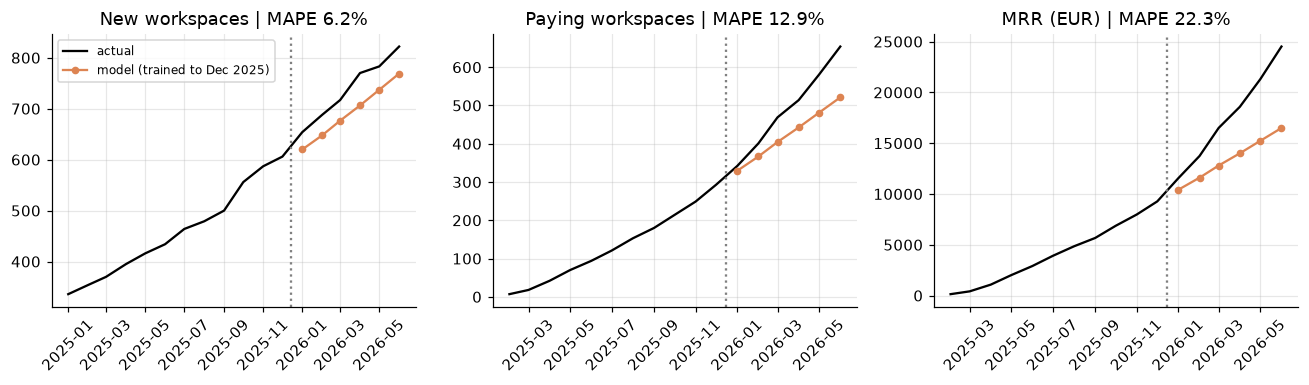

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, k, title in zip(axes, ["new_ws", "paying", "mrr"], ["New workspaces", "Paying workspaces", "MRR (EUR)"]):
    ax.plot(hist.index, {"new_ws": new_ws.sum(axis=1), "paying": mrr["paying"], "mrr": mrr["mrr"]}[k].reindex(hist.index), color="black", label="actual")
    ax.plot(result.index, result["pred_" + k], color="#DD8452", marker="o", ms=4, label="model (trained to Dec 2025)")
    ax.axvline(pd.Timestamp("2025-12-15"), color="grey", ls=":")
    ax.set_title(f"{title} | MAPE {mape[k]:.1%}")
    ax.tick_params(axis="x", rotation=45)
axes[0].legend(fontsize=8)
save("fig14_backtest")

In [42]:
# where does the error come from? replace one parameter by its value observed after Dec 2025
checks = {"model as trained": params_bt}
p = params_bt.copy()
p["conversion"] = mature.loc[mature["after_change"], "upgraded"].mean()
checks["+ post-change conversion"] = p
p = p.copy()
p["arpa"] = mrr.loc["2026-01-01":, "arpa"].mean()
checks["+ observed 2026 ARPA"] = p

errors = {}
for name, p in checks.items():
    out = simulate(p, "2026-01-01", 6, actual_spend, hist[hist.index <= "2025-12-01"])
    errors[name] = {k: (abs(out[c] - actual[c]) / actual[c]).mean() for k, c in [("MAPE paying", "paying"), ("MAPE MRR", "mrr")]}
(pd.DataFrame(errors).T * 100).round(1)

,MAPE paying,MAPE MRR
model as trained,12.9,22.3
+ post-change conversion,4.0,14.4
+ observed 2026 ARPA,4.0,6.2


**Backtest results.** Acquisition is well predicted (MAPE 6 %), which confirms that sign-ups are a mechanical function of spend, organic trend and loop. Paying workspaces (MAPE 13 %) and MRR (MAPE 22 %) are **underestimated**, and the error grows over time.

The decomposition shows why. In December 2025, the onboarding change was too recent for its effect on conversion to be visible in mature cohorts: the model still used the pre-change conversion. Replacing it with the post-change value brings the error on paying workspaces from 12.9 % to 4.0 %; adding the observed 2026 ARPA brings the MRR error from 22.3 % to 6.2 %. The lesson matches the course: *good growth models do not predict the future, they show how fragile your beliefs are* — here, the model is fragile exactly where the business changed.

### 6.3 Three scenarios (July 2026 – June 2027)

The model is recalibrated on all the data, with the post-change conversion. All scenarios share the same spend plan (current trends: paid search +4 % per month, SEO +150 € per month, partners flat). Each scenario lever is a value **observed in the data**, not an assumption.

| Lever | Pessimistic | Base | Optimistic |
|---|---|---|---|
| conversion | pre-change level (8.1 %) | post-change (10.8 %) | activated workspaces after the change (14.4 %) |
| monthly churn | teams of 1–10 (4.4 %) | last 6 months (3.1 %) | Business plan (2.1 %) |
| loop rate | pre-change mean (1.7 %) | last 6 months (2.0 %) | best month observed (2.2 %) |
| ARPA | flat | flat | H1 2026 trend (+2.9 % per month) |

In [43]:
params = calibrate("2026-06-01", "2026-04-01")
# post-change conversion: cohorts created between 15 Sep 2025 and 31 Mar 2026
params["conversion"] = mature.loc[mature["after_change"], "upgraded"].mean()
params["arpa"] = mrr["arpa"].iloc[-1]

def spend_plan(paid_growth, seo_step, months=12):
    idx = pd.date_range("2026-07-01", periods=months, freq="MS")
    last = sp.iloc[-1]
    return pd.DataFrame({
        "paid_search": [last["paid_search"] * (1 + paid_growth) ** (t + 1) for t in range(months)],
        "content_seo": [last["content_seo"] + seo_step * (t + 1) for t in range(months)],
        "partners": [last["partners"]] * months,
    }, index=idx)

base_spend = spend_plan(params["paid_spend_growth"], params["seo_spend_step"])
{k: (round(v, 4) if isinstance(v, float) else v) for k, v in params.items()}

{'cps_paid_search': np.float64(55.1577),
 'cps_content_seo': np.float64(32.2095),
 'cps_partners': np.float64(92.5926),
 'organic_growth': np.float64(0.0303),
 'loop_rate': np.float64(0.0201),
 'conversion': np.float64(0.1078),
 'churn': np.float64(0.0308),
 'arpa': np.float64(37.4801),
 'seo_spend_step': np.float64(150.0),
 'paid_spend_growth': np.float64(0.04),
 'lag': {1: 0.09141274238227147,
  2: 0.39058171745152354,
  3: 0.36426592797783935,
  4: 0.15373961218836565}}

In [44]:
# every lever of the scenarios is a value observed in the data
before = mature[~mature["after_change"]]
arpa_growth = (mrr["arpa"].iloc[-1] / mrr["arpa"].iloc[-7]) ** (1 / 6) - 1

optimistic = params.copy()
optimistic["conversion"] = mature.loc[mature["after_change"] & mature["activated"], "upgraded"].mean()   # every new workspace behaves like an activated one
optimistic["churn"] = plan_seg.loc["business", "monthly_churn"]                                           # churn of business plan
optimistic["loop_rate"] = loop_rate.max()                                                                 # best monthly loop rate observed
optimistic["arpa_growth"] = arpa_growth                                                                   # seat expansion of H1 2026

pessimistic = params.copy()
pessimistic["conversion"] = before["upgraded"].mean()                                                     # back to pre-change conversion
pessimistic["churn"] = seg.loc["1-10", "monthly_churn"]                                                   # churn of small teams
pessimistic["loop_rate"] = loop_rate[loop_rate.index < "2025-09-01"].mean()                               # pre-change loop rate

scenarios = {"Pessimistic": pessimistic, "Base": params, "Optimistic": optimistic}
lever_table = pd.DataFrame(scenarios).loc[["conversion", "churn", "loop_rate"]].T
lever_table["arpa_growth"] = [0, 0, arpa_growth]
print(lever_table.round(4))

runs = {}
for name, p in scenarios.items():
    out = simulate(p, "2026-07-01", 12, base_spend, hist)
    if p.get("arpa_growth"):
        out["mrr"] = out["paying"] * p["arpa"] * (1 + p["arpa_growth"]) ** np.arange(1, 13)
    runs[name] = out

summary = pd.DataFrame({n: {"new workspaces (12m)": r["new_workspaces"].sum(), "paying Jun 2027": r["paying"].iloc[-1],
                            "MRR Jun 2027": r["mrr"].iloc[-1], "ARR Jun 2027": r["mrr"].iloc[-1] * 12,
                            "MRR growth vs Jun 2026": r["mrr"].iloc[-1] / mrr["mrr"].iloc[-1] - 1} for n, r in runs.items()}).T
summary.round(2)

            conversion     churn loop_rate  arpa_growth
Pessimistic   0.081252   0.04441  0.016828       0.0000
Base          0.107783  0.030769  0.020119       0.0000
Optimistic    0.144075  0.021244  0.021878       0.0286


,new workspaces (12m),paying Jun 2027,MRR Jun 2027,ARR Jun 2027,MRR growth vs Jun 2026
Pessimistic,12514.27,1122.19,42059.79,504717.47,0.72
Base,13173.96,1546.31,57955.82,695469.81,1.36
Optimistic,13535.36,2074.13,109050.25,1308602.96,3.45


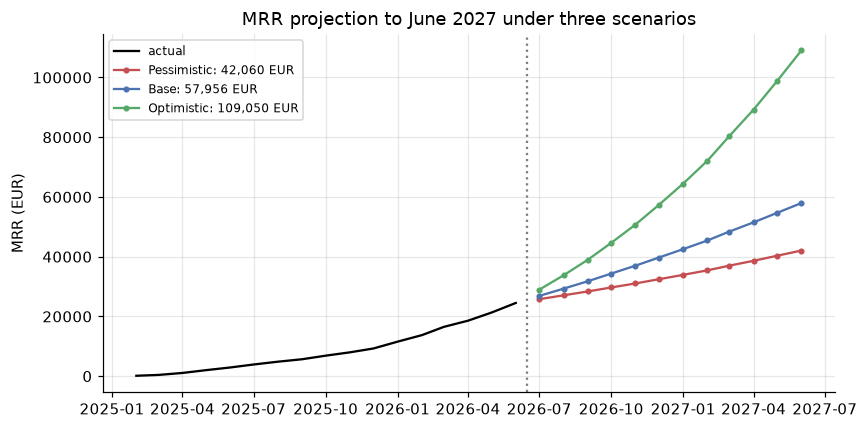

In [45]:
sc_colors = {"Pessimistic": "#C44E52", "Base": "#4C72B0", "Optimistic": "#55A868"}
plt.figure(figsize=(8, 4))
plt.plot(mrr.index, mrr["mrr"], color="black", label="actual")
for name, out in runs.items():
    plt.plot(out.index, out["mrr"], color=sc_colors[name], marker="o", ms=3, label=f"{name}: {out['mrr'].iloc[-1]:,.0f} EUR")
plt.axvline(pd.Timestamp("2026-06-15"), color="grey", ls=":")
plt.ylabel("MRR (EUR)")
plt.title("MRR projection to June 2027 under three scenarios")
plt.legend(fontsize=8)
save("fig15_scenarios")

In June 2027, MRR reaches about **42 k€ (pessimistic), 58 k€ (base) and 109 k€ (optimistic)**, i.e. an ARR of 0.50, 0.70 and 1.31 M€. The number of new workspaces barely changes between scenarios (12.5 k to 13.5 k): the difference is made by what happens **after** the sign-up — activation, conversion, retention and team size — not by acquisition.

### 6.4 Sensitivity: one lever at a time

As in the "what if" experiments of the course, each lever is moved by ±20 % while the others stay at the base value.

In [46]:
# one lever at a time, +/- 20 %, effect on MRR in June 2027 (base = 100)
base_mrr = runs["Base"]["mrr"].iloc[-1]
levers = {"conversion": "conversion", "churn": "churn", "loop_rate": "loop rate",
          "arpa": "ARPA", "cps_paid_search": "paid search cost per signup"}
sens = []
for k, label in levers.items():
    row = {"lever": label}
    for f in [0.8, 1.2]:
        p = params.copy()
        p[k] = params[k] * f
        row[f"x{f}"] = simulate(p, "2026-07-01", 12, base_spend, hist)["mrr"].iloc[-1] / base_mrr * 100 - 100
    sens.append(row)

# +20 % paid search budget, same cost per signup
p_plan = base_spend.copy()
p_plan["paid_search"] *= 1.2
sens.append({"lever": "paid search budget", "x0.8": np.nan,
             "x1.2": simulate(params, "2026-07-01", 12, p_plan, hist)["mrr"].iloc[-1] / base_mrr * 100 - 100})
sens = pd.DataFrame(sens).set_index("lever")
sens.round(1)

,x0.8,x1.2
lever,,
conversion,-14.2,14.2
churn,4.4,-4.2
loop rate,-3.5,3.6
ARPA,-20.0,20.0
paid search cost per signup,4.1,-2.8
paid search budget,NaN,3.3


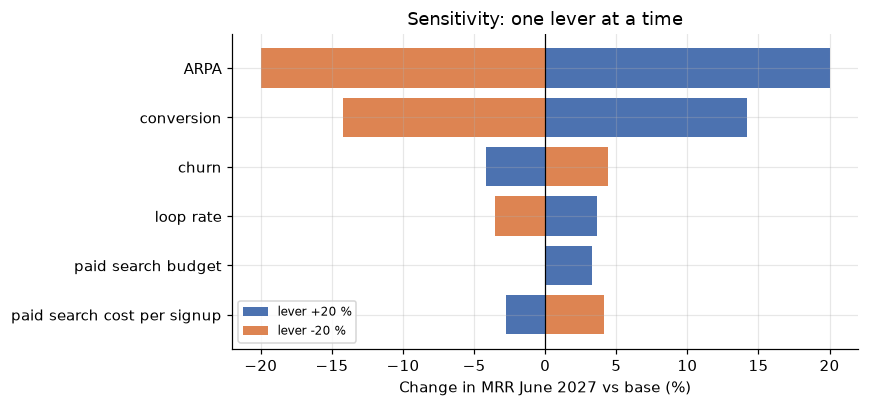

In [47]:
order = sens["x1.2"].abs().sort_values().index
plt.figure(figsize=(8, 3.8))
plt.barh(order, sens.loc[order, "x1.2"], color="#4C72B0", label="lever +20 %")
plt.barh(order, sens.loc[order, "x0.8"], color="#DD8452", label="lever -20 %")
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Change in MRR June 2027 vs base (%)")
plt.title("Sensitivity: one lever at a time")
plt.legend(fontsize=8)
save("fig16_sensitivity")

- ARPA (±20 %) and conversion (±14 %) are the strongest levers on a 12-month horizon.
- Churn (±4 %) and loop rate (±4 %) matter less over one year, but their effect compounds over longer horizons.
- **+20 % of paid search budget only adds 3.3 % of MRR**, less than a 20 % improvement of conversion or of the loop. This answers the course exercise "product improvement or paid ads?": with Tasko's current parameters, the product levers win.

## 7. A/B test plan

**Hypothesis.** Paid search sign-ups rarely form a team (activation 35 % after the change, against 60–70 % elsewhere), and the onboarding change did not lift their conversion. A team-setup step adapted to these users (e.g. a guided "invite two teammates" step shown before the first project) should raise their activation and then their conversion.

- **Population**: new workspaces acquired through paid search, randomised 50/50 at creation.
- **Primary metric**: activation (2+ teammates within 30 days) — a leading indicator, observable in 30 days.
- **Secondary metric**: paid within 90 days. **Guardrails**: churn of paying workspaces, seats per workspace.
- **Test**: two-sided test on two proportions, α = 5 %, power = 80 %.

In [48]:
def sample_size(p1, p2, z_alpha=1.96, z_beta=0.84):
    """Workspaces per arm for a two-sided test on two proportions (alpha 5 %, power 80 %)."""
    return int(np.ceil((z_alpha + z_beta) ** 2 * (p1 * (1 - p1) + p2 * (1 - p2)) / (p1 - p2) ** 2))

ps_recent = mature[(mature["acquisition_channel"] == "paid_search") & mature["after_change"]]
p_act = ps_recent["activated"].mean()
p_conv = ps_recent["paid_90d"].mean()
monthly_ps = new_ws["paid_search"].tail(3).mean()

plan = []
for metric, p1 in [("activation (2+ teammates in 30 days)", p_act), ("paid within 90 days", p_conv)]:
    for uplift in [0.02, 0.05, 0.08]:
        n = sample_size(p1, p1 + uplift)
        plan.append({"metric": metric, "baseline": round(p1, 3), "MDE (pts)": uplift * 100,
                     "n per arm": n, "months of paid search sign-ups": round(2 * n / monthly_ps, 1)})
print(f"Paid search sign-ups per month (last 3 months): {monthly_ps:.0f}")
pd.DataFrame(plan)

Paid search sign-ups per month (last 3 months): 204


,metric,baseline,MDE (pts),n per arm,months of paid search sign-ups
0,activation (2+ teammates in 30 days),0.345,2.0,8969,87.9
1,activation (2+ teammates in 30 days),0.345,5.0,1458,14.3
2,activation (2+ teammates in 30 days),0.345,8.0,577,5.7
3,paid within 90 days,0.065,2.0,2710,26.6
4,paid within 90 days,0.065,5.0,509,5.0
5,paid within 90 days,0.065,8.0,226,2.2


With about 204 paid search sign-ups per month, a 5-point lift in activation needs 14 months of traffic, whereas an 8-point lift needs 577 workspaces per arm, i.e. about 6 months. A test powered on a 2-point lift of conversion would last more than two years, and each result would arrive 90 days late. The plan is therefore to **test on activation with a minimum detectable effect of 8 points** (34.5 % → 42.5 %), then follow conversion as a secondary metric. The onboarding change of September 2025 lifted activation by 11 points on paid search, so an 8-point effect is plausible.

Ethical safeguard (course, *dark patterns*): the invitation step must stay optional and transparent — no forced sharing, no automatic invitations of contacts.

## Conclusion

- Growth is **product-led after the sign-up**: activation (a team of three) drives conversion, and the base feeds a loop that already brings one new workspace in five.
- Paid search buys sign-ups at a constant price but poor teams: LTV : CAC of 1.2 on revenue, payback of 31 months. Content SEO is the healthiest paid channel; partners destroy value.
- The September 2025 onboarding change is the most important event of the period: +20 points of activation, +2.7 points of conversion and a stronger loop, without hurting retention.
- The North Star Metric should be the number of workspaces reaching a team of three users, and the next euro should go to activation rather than to paid search.